In [3]:
from rdkit import Chem
from rdkit.Chem import Descriptors, Draw


In [ ]:
#PCB-153, a common persistent PCB congener, is a known endocrine disruptor. Let's explore its structure and some of its properties.

In [4]:
pcb153 = Chem.MolFromSmiles('Clc1ccc(c(Cl)c1Cl)-c1ccc(Cl)c(Cl)c1Cl')

In [5]:
print("Molecular weight:", round(Descriptors.MolWt(pcb153), 1))

Molecular weight: 360.9


In [6]:
print("logP:", round(Descriptors.MolLogP(pcb153), 2))

logP: 7.27


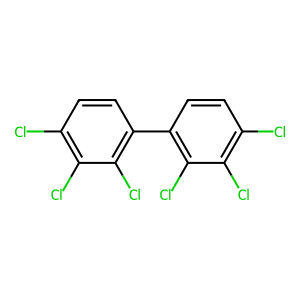

In [7]:
Draw.MolToImage(pcb153, size=(300, 300), kekulize=True, wedgeBonds=True)

In [8]:
import pandas as pd
from rdkit import Chem, DataStructs
from rdkit.Chem import Descriptors, AllChem


In [15]:
chemicals = {
    "PCB-153": "Clc1ccc(c(Cl)c1Cl)-c1ccc(Cl)c(Cl)c1Cl",
    "TCDD (dioxin)": "Clc1cc20c3cc(Cl)c(Cl)cc30c2cc1Cl",
    "PFOA": "OC(=O)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)F",
    "PFOS": "OS(=O)(=O)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)F",
}

rows = []
for name, smi in chemicals.items():
    mol = Chem.MolFromSmiles(smi)
    rows.append({
        "chemical": name,
        "mol_weight": round(Descriptors.MolWt(mol), 1), #size
        "logP": round(Descriptors.MolLogP(mol), 2), #lipophilicity
        "TPSA": round(Descriptors.TPSA(mol), 1),    #polarity  
        "halogens": sum(a.GetSymbol() in ('F', 'Cl') for a in mol.GetAtoms()),
    })

df = pd.DataFrame(rows)
print(df)


ArgumentError: Python argument types in
    None._CalcMolWt(NoneType)
did not match C++ signature:
    _CalcMolWt(class RDKit::ROMol mol, bool onlyHeavy=False)

In [16]:
import pandas as pd
from rdkit import Chem, DataStructs
from rdkit.Chem import Descriptors, AllChem

chemicals = {
    "PCB-153": "Clc1ccc(c(Cl)c1Cl)-c1ccc(Cl)c(Cl)c1Cl",
    "TCDD (dioxin)": "Clc1cc2Oc3cc(Cl)c(Cl)cc3Oc2cc1Cl",
    "PFOA": "OC(=O)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)F",
    "PFOS": "OS(=O)(=O)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)F",
}

rows = []
for name, smi in chemicals.items():
    mol = Chem.MolFromSmiles(smi)
    rows.append({
        "chemical": name,
        "mol_weight": round(Descriptors.MolWt(mol), 1),
        "logP": round(Descriptors.MolLogP(mol), 2),        # lipophilicity
        "TPSA": round(Descriptors.TPSA(mol), 1),           # polarity
        "halogens": sum(a.GetSymbol() in ("F", "Cl") for a in mol.GetAtoms()),
    })

df = pd.DataFrame(rows)
print(df)

# Read-across starts with similarity: how alike are PFOA and PFOS?
fp = lambda s: AllChem.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(s), 2, 2048)
sim = DataStructs.TanimotoSimilarity(fp(chemicals["PFOA"]), fp(chemicals["PFOS"]))
print(f"\nPFOA vs PFOS Tanimoto similarity: {sim:.2f}")

        chemical  mol_weight  logP  TPSA  halogens
0        PCB-153       360.9  7.27   0.0         6
1  TCDD (dioxin)       322.0  6.20  18.5         4
2           PFOA       414.1  4.45  37.3        15
3           PFOS       500.1  4.84  54.4        17

PFOA vs PFOS Tanimoto similarity: 0.40
